In [1]:
!nvidia-smi

Sun Oct  6 10:07:26 2024       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.104.05             Driver Version: 535.104.05   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off | 00000000:00:04.0 Off |                    0 |
| N/A   32C    P0              46W / 400W |      2MiB / 40960MiB |      0%      Default |
|                                         |                      |             Disabled |
+-----------------------------------------+----------------------+--

**NOTE:** To make it easier for us to manage datasets, images and models we create a `HOME` constant.

In [2]:
import os
HOME = os.getcwd()
print(HOME)

/content


## Install YOLO11 via Ultralytics

In [3]:
%pip install ultralytics supervision roboflow
import ultralytics
ultralytics.checks()

Ultralytics 8.3.5 🚀 Python-3.10.12 torch-2.4.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)
Setup complete ✅ (12 CPUs, 83.5 GB RAM, 36.4/235.7 GB disk)


## Fine-tune YOLO11 on custom dataset

In [4]:
!mkdir {HOME}/datasets
%cd {HOME}/datasets

from google.colab import userdata
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="2ffl1zZqwCdjI4cj61VQ")
project = rf.workspace("work-r9avx").project("save_sc")
version = project.version(2)
dataset = version.download("yolov11")


/content/datasets
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to SAVE_SC-2 in yolov11:: 100%|██████████| 3028/3028 [00:00<00:00, 7327.56it/s]


## Custom Training

In [5]:
%cd {HOME}

!yolo task=detect mode=train model=yolo11m.pt data={dataset.location}/data.yaml epochs=600 imgsz=640 plots=True

/content
100% 38.8M/38.8M [00:00<00:00, 197MB/s]
Ultralytics 8.3.5 🚀 Python-3.10.12 torch-2.4.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)
engine/trainer: task=detect, mode=train, model=yolo11m.pt, data=/content/datasets/SAVE_SC-2/data.yaml, epochs=600, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False, save_

**NOTE:** The results of the completed training are saved in `{HOME}/runs/detect/train/`. Let's examine them.

In [6]:
!ls {HOME}/runs/detect/train/

args.yaml					    PR_curve.png	   val_batch0_pred.jpg
confusion_matrix_normalized.png			    R_curve.png		   val_batch1_labels.jpg
confusion_matrix.png				    results.csv		   val_batch1_pred.jpg
events.out.tfevents.1728209272.b8e9979918ce.1163.0  results.png		   val_batch2_labels.jpg
F1_curve.png					    train_batch0.jpg	   val_batch2_pred.jpg
labels_correlogram.jpg				    train_batch1.jpg	   weights
labels.jpg					    train_batch2.jpg
P_curve.png					    val_batch0_labels.jpg


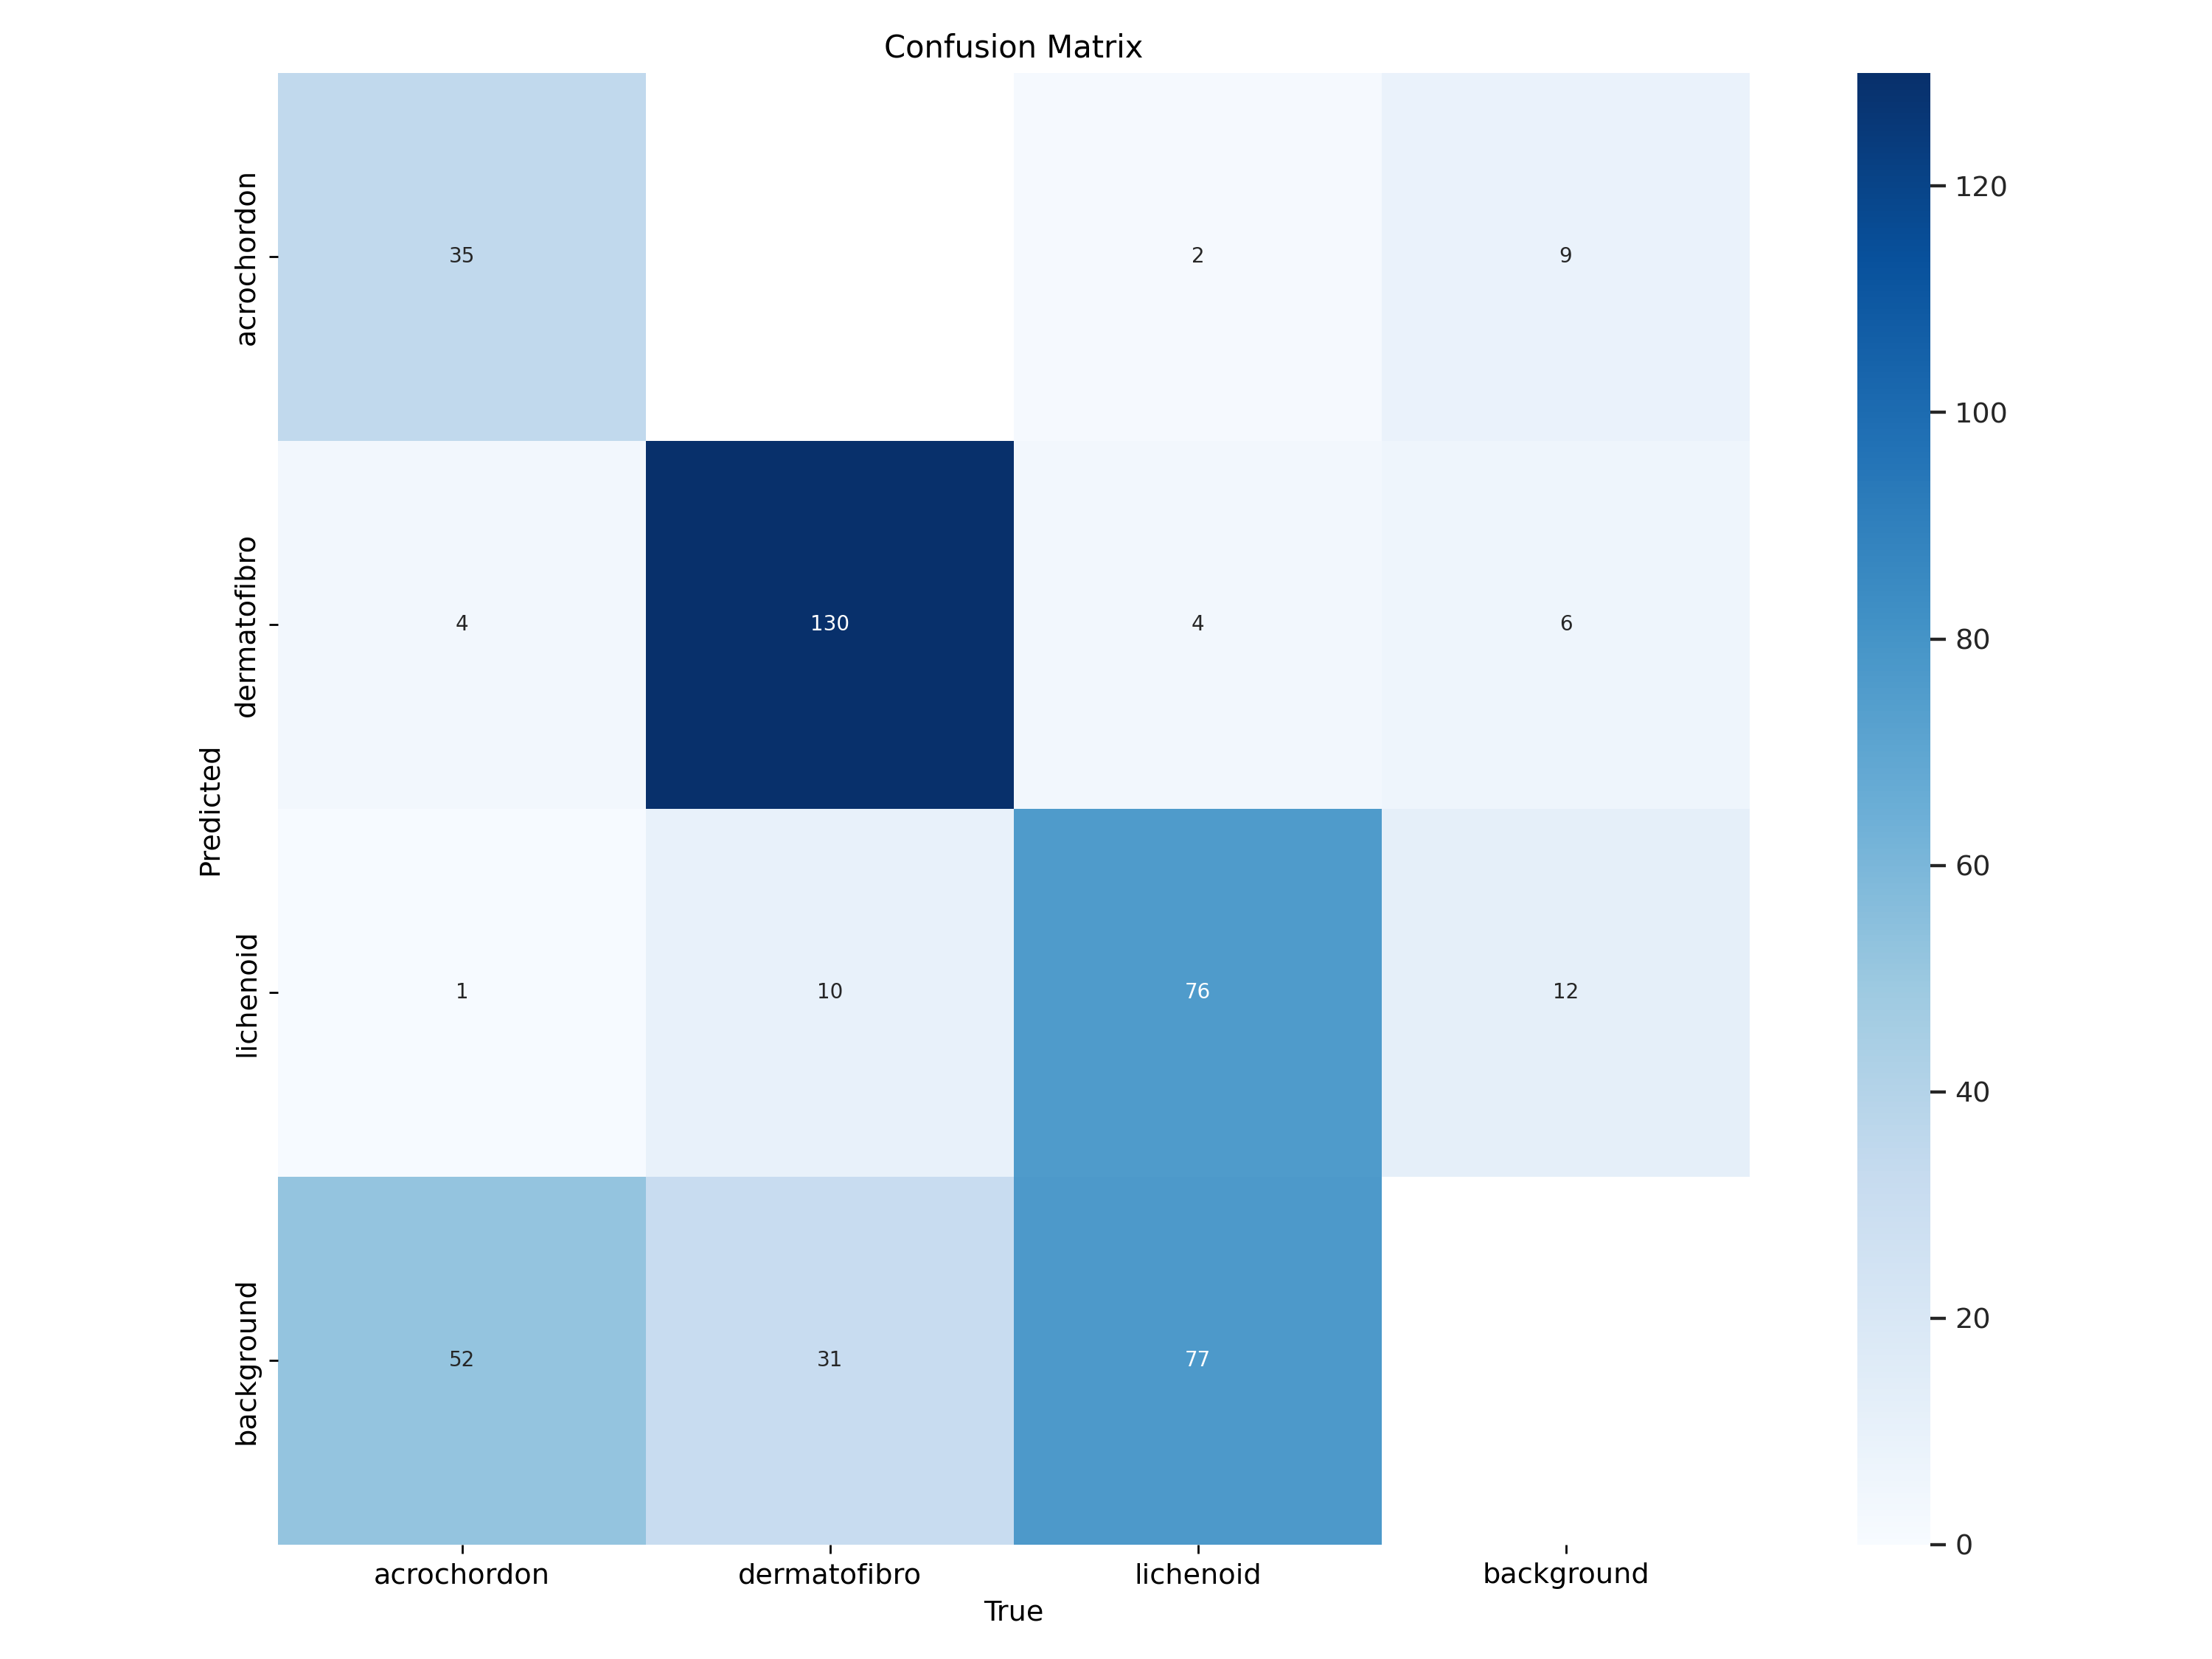

In [7]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/detect/train/confusion_matrix.png', width=600)

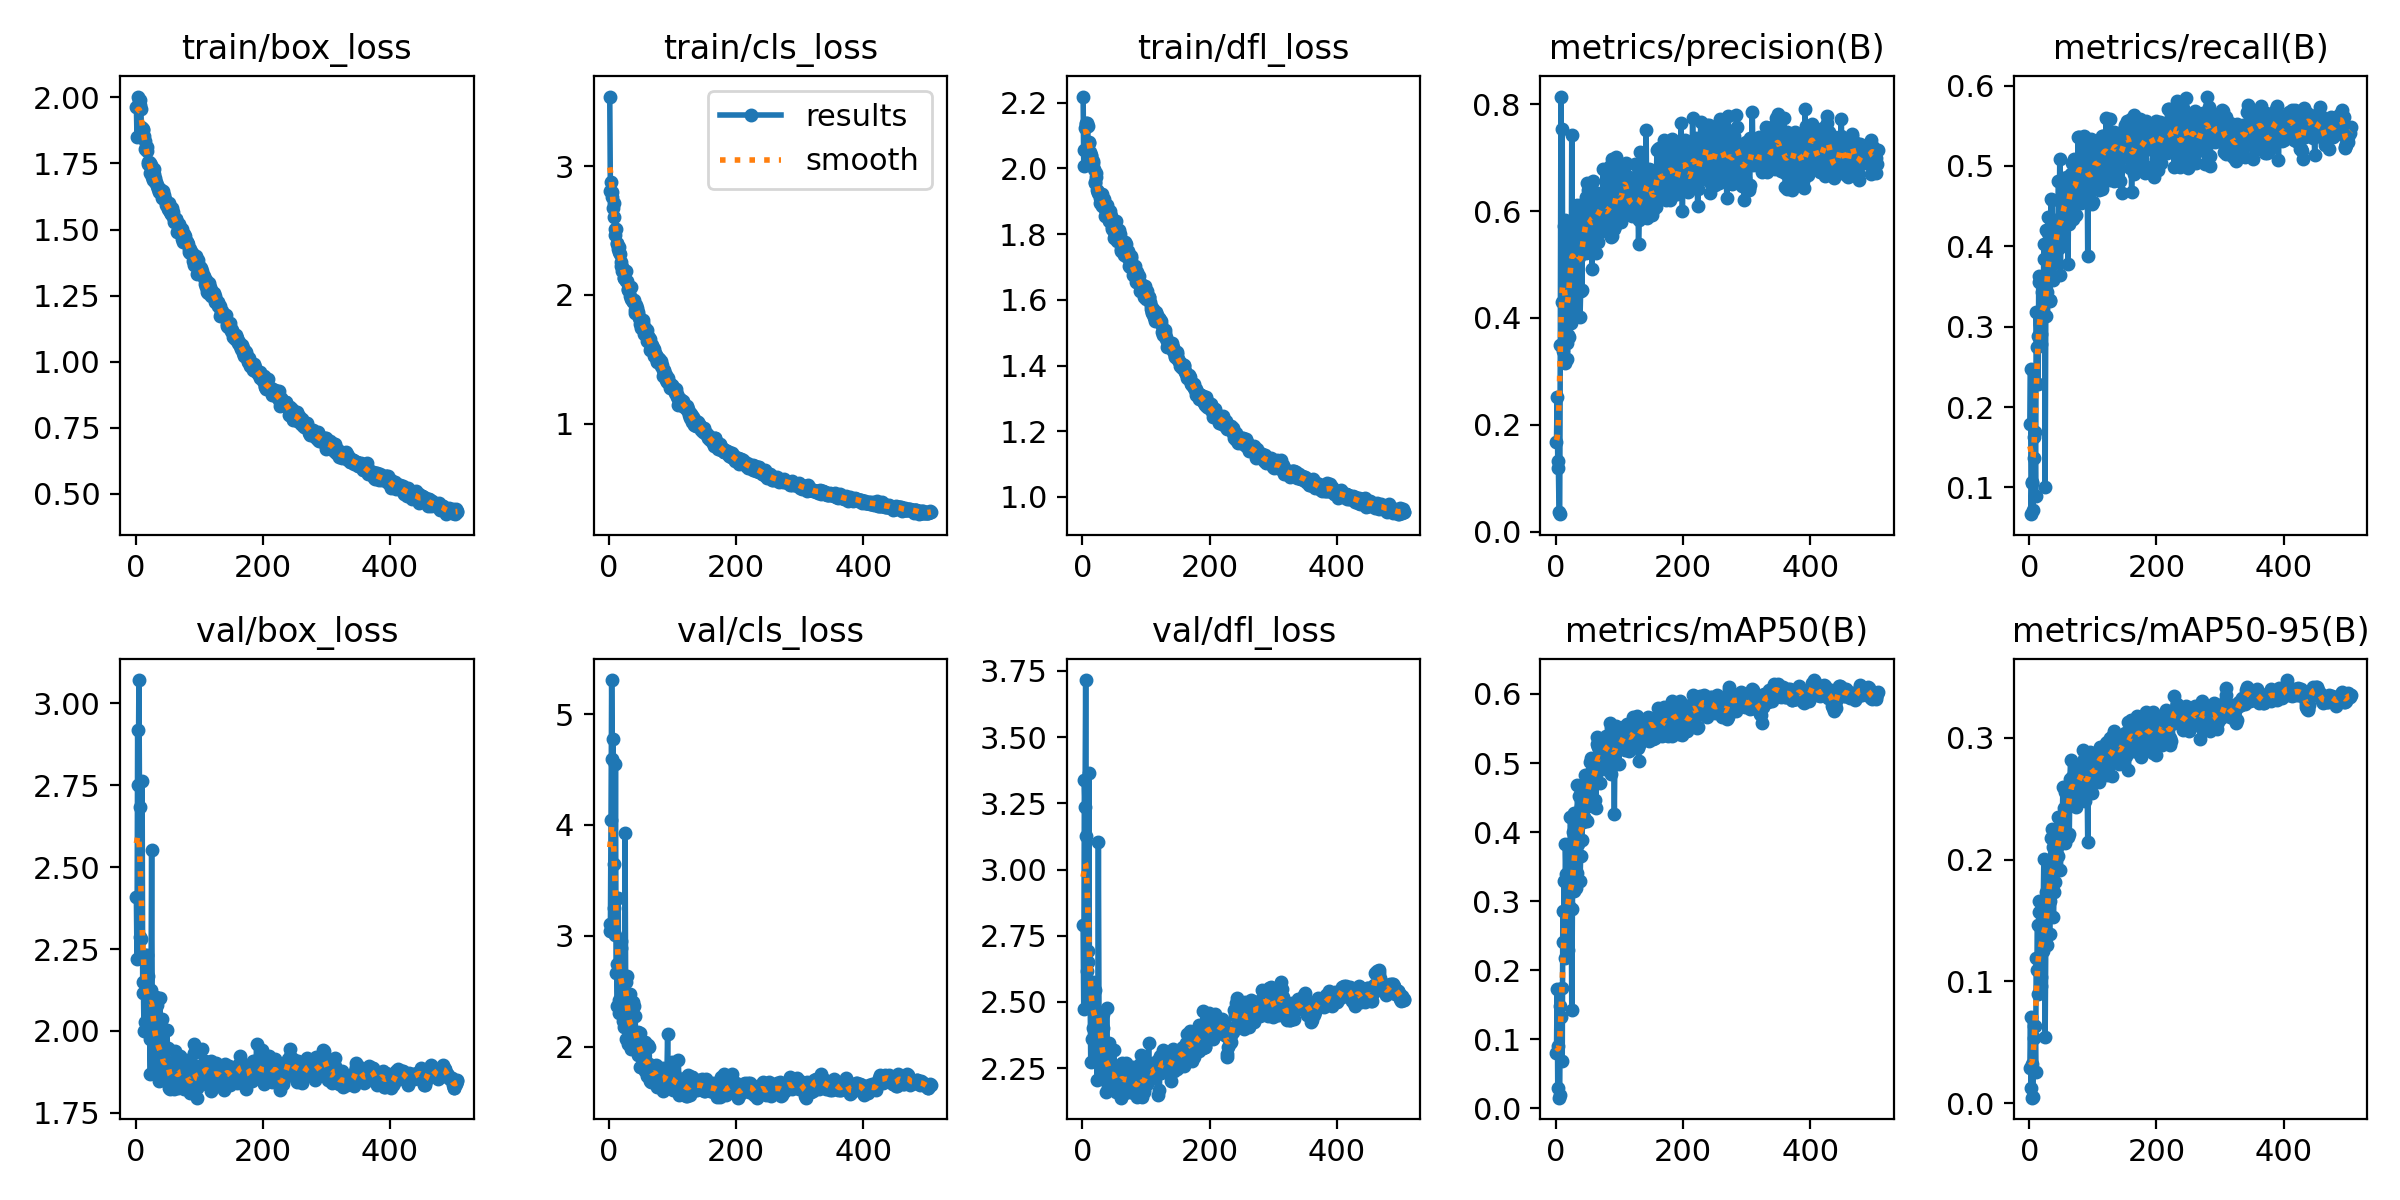

In [8]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/detect/train/results.png', width=600)

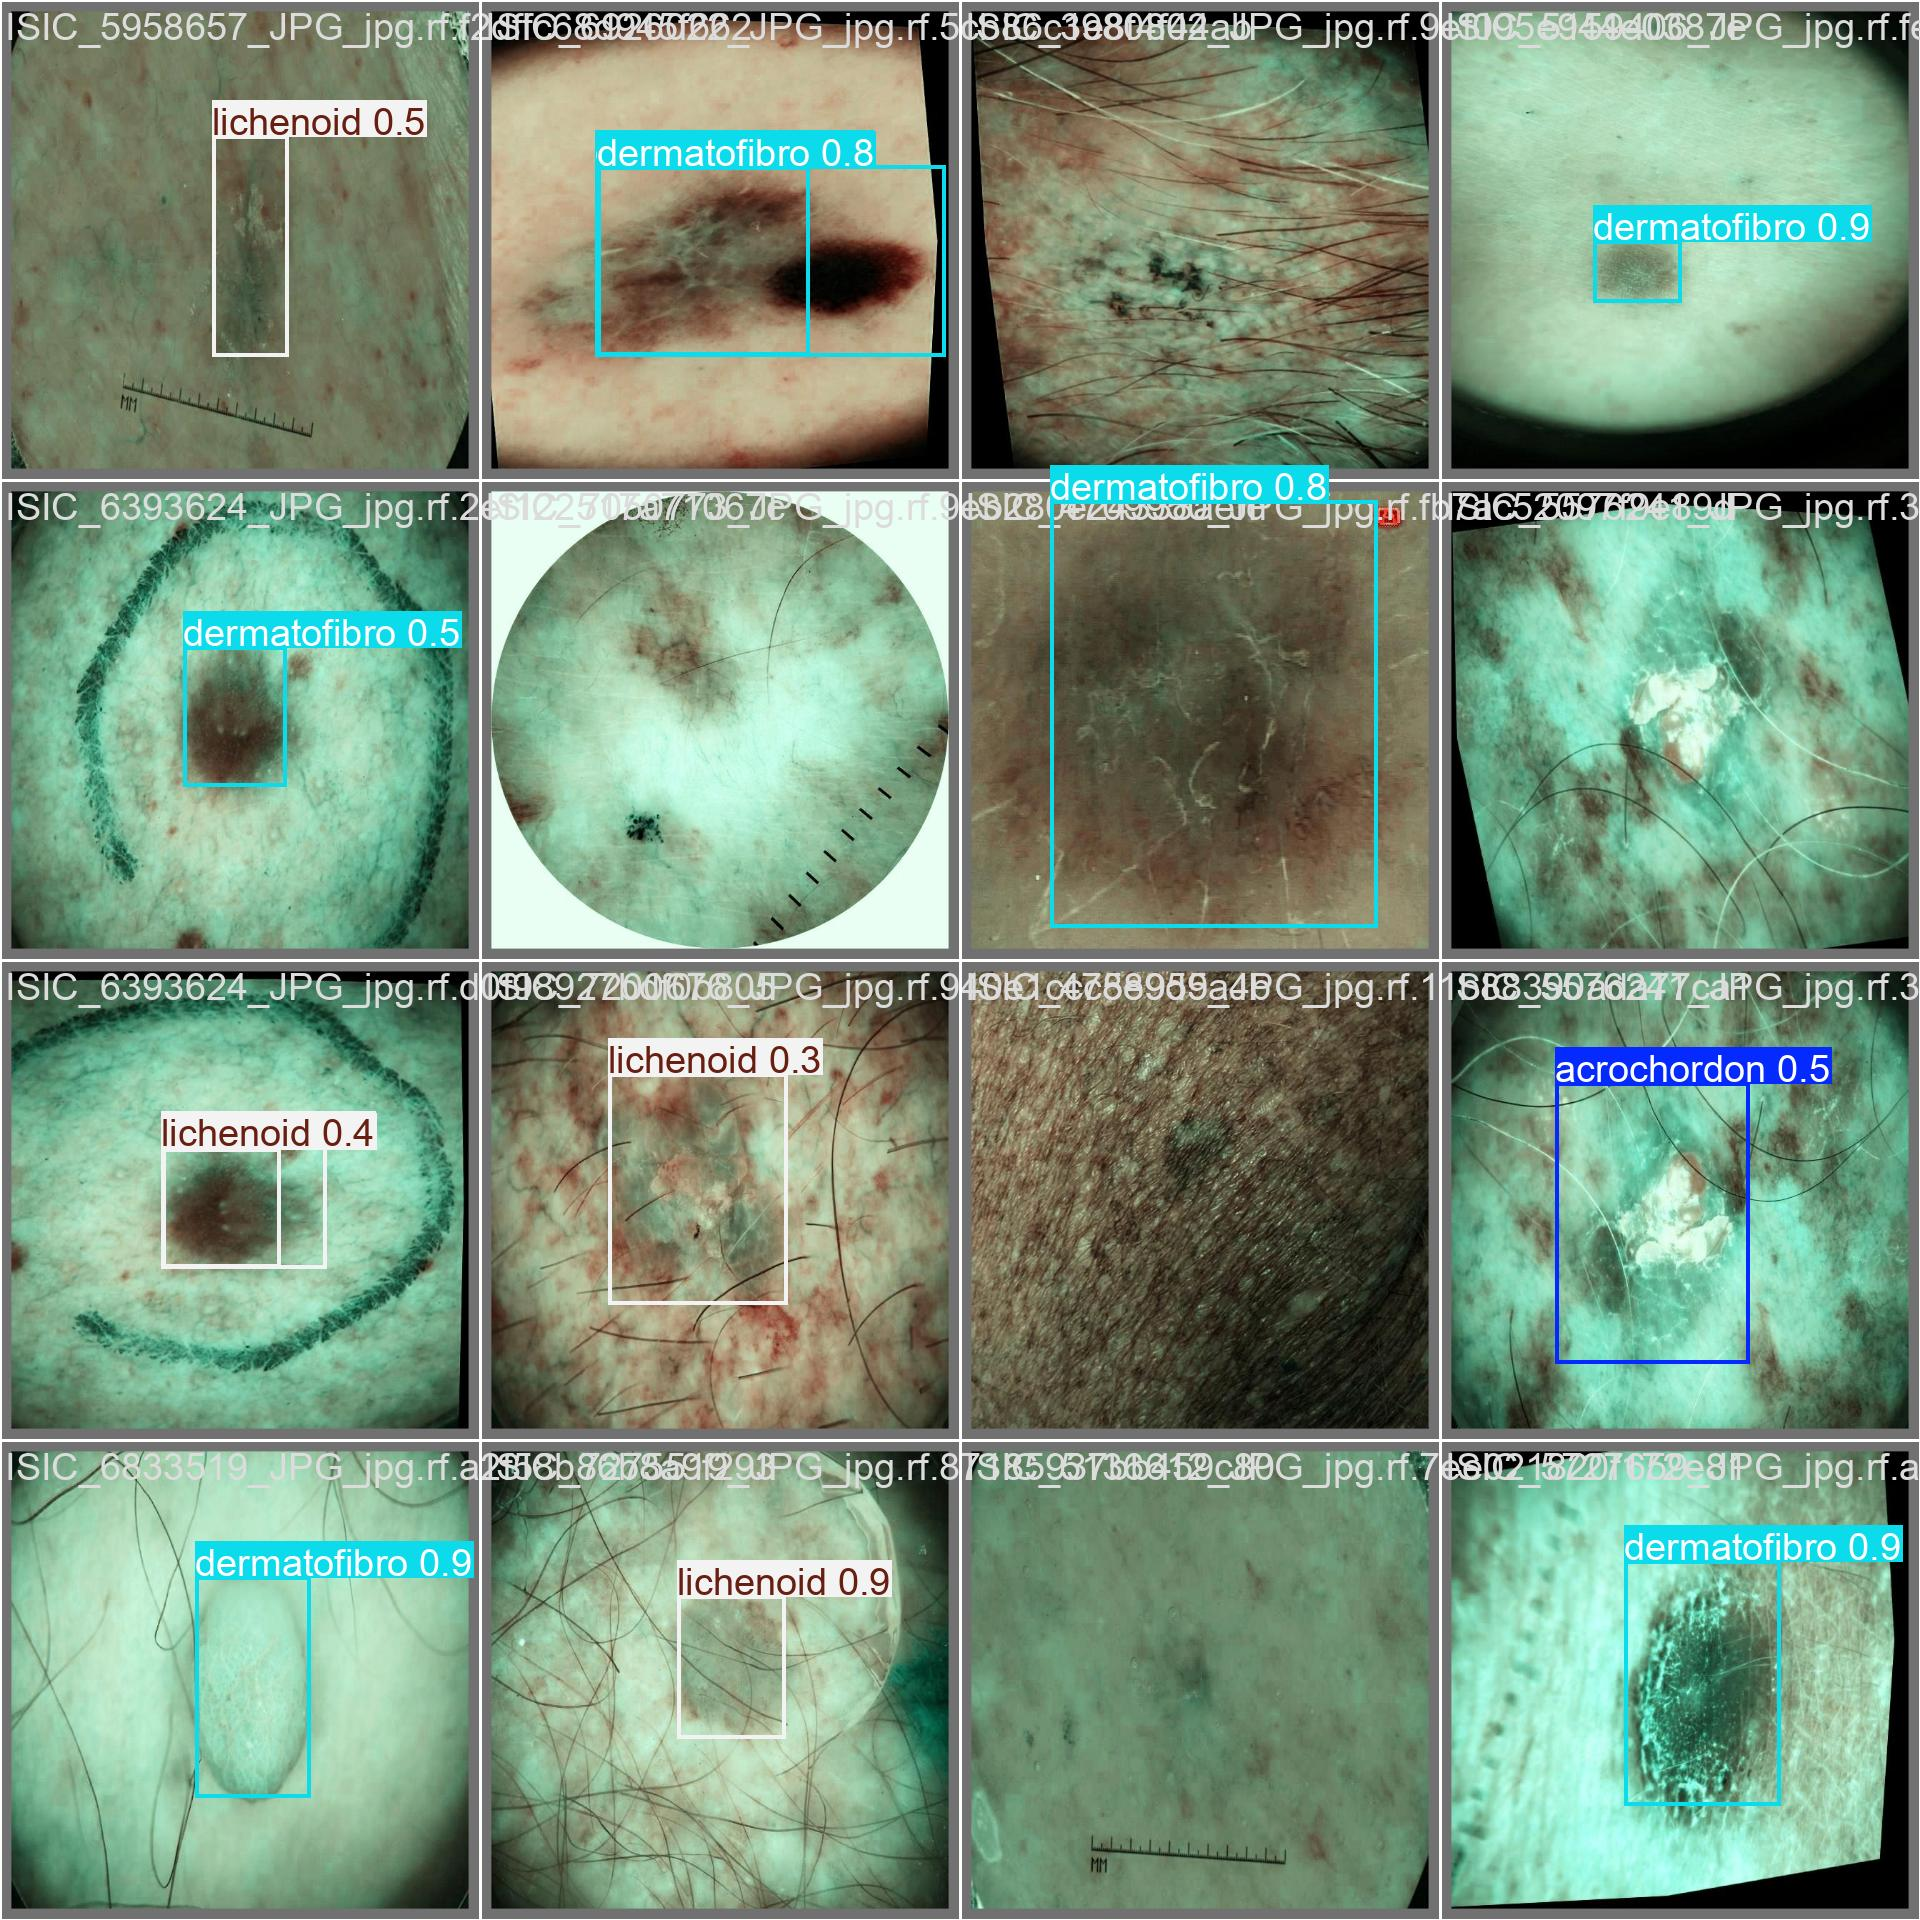

In [9]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/detect/train/val_batch0_pred.jpg', width=600)

## Validate fine-tuned model

In [10]:
!yolo task=detect mode=val model={HOME}/runs/detect/train/weights/best.pt data={dataset.location}/data.yaml

Ultralytics 8.3.5 🚀 Python-3.10.12 torch-2.4.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)
YOLO11m summary (fused): 303 layers, 20,032,345 parameters, 0 gradients, 67.7 GFLOPs
val: Scanning /content/datasets/SAVE_SC-2/valid/labels.cache... 303 images, 0 backgrounds, 0 corrupt: 100% 303/303 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% 19/19 [00:03<00:00,  5.26it/s]
                   all        303        422      0.743      0.542       0.62      0.348
           acrochordon         53         92      0.709      0.398      0.479      0.278
          dermatofibro        145        171      0.861      0.763       0.84      0.476
             lichenoid        105        159      0.658      0.465      0.541      0.289
Speed: 0.9ms preprocess, 3.2ms inference, 0.0ms loss, 3.5ms postprocess per image
Results saved to runs/detect/val
💡 Learn more at https://docs.ultralytics.com/modes/val


**Test**


In [11]:
!yolo task=detect mode=val model={HOME}/runs/detect/train/weights/best.pt data={dataset.location}/data1.yaml

Ultralytics 8.3.5 🚀 Python-3.10.12 torch-2.4.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)
YOLO11m summary (fused): 303 layers, 20,032,345 parameters, 0 gradients, 67.7 GFLOPs
val: Scanning /content/datasets/SAVE_SC-2/test/labels... 150 images, 0 backgrounds, 0 corrupt: 100% 150/150 [00:00<00:00, 1085.73it/s]
val: New cache created: /content/datasets/SAVE_SC-2/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% 10/10 [00:02<00:00,  3.74it/s]
                   all        150        217      0.775      0.579      0.627      0.373
           acrochordon         33         60      0.581      0.433      0.416      0.224
          dermatofibro         69         75      0.934      0.827      0.916      0.552
             lichenoid         48         82      0.809      0.476      0.548      0.343
Speed: 1.4ms preprocess, 3.3ms inference, 0.0ms loss, 8.7ms postprocess per image
Results saved to runs/detect/val2
💡 Learn more at ht

## Inference with custom model

In [12]:
!yolo task=detect mode=predict model={HOME}/runs/detect/train/weights/best.pt conf=0.25 source={dataset.location}/test/images save=True

Ultralytics 8.3.5 🚀 Python-3.10.12 torch-2.4.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)
YOLO11m summary (fused): 303 layers, 20,032,345 parameters, 0 gradients, 67.7 GFLOPs

image 1/150 /content/datasets/SAVE_SC-2/test/images/ISIC_0012113_JPG_jpg.rf.44c05e7264078fa8d805ac7728c1b69c.jpg: 640x640 1 lichenoid, 13.1ms
image 2/150 /content/datasets/SAVE_SC-2/test/images/ISIC_0012194_JPG_jpg.rf.a60e0d3753977b4b89529502566f58d1.jpg: 640x640 1 lichenoid, 12.4ms
image 3/150 /content/datasets/SAVE_SC-2/test/images/ISIC_0012251_JPG_jpg.rf.7e5863171ca9e64f3599fccbddad1fbc.jpg: 640x640 1 lichenoid, 11.8ms
image 4/150 /content/datasets/SAVE_SC-2/test/images/ISIC_0012336_JPG_jpg.rf.4a5004168ba181ebf324ee55bb536d6f.jpg: 640x640 1 lichenoid, 11.6ms
image 5/150 /content/datasets/SAVE_SC-2/test/images/ISIC_0012421_JPG_jpg.rf.ae0ae4b72967aeae2f02f887e6d3f8b9.jpg: 640x640 1 dermatofibro, 11.6ms
image 6/150 /content/datasets/SAVE_SC-2/test/images/ISIC_0012474_JPG_jpg.rf.ea22498fe3234169f519a7b7cb7ea5f

**NOTE:** Let's take a look at few results.

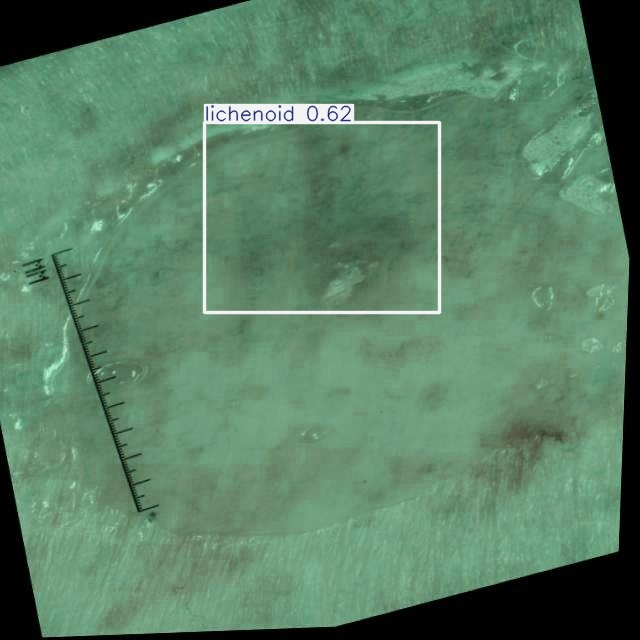

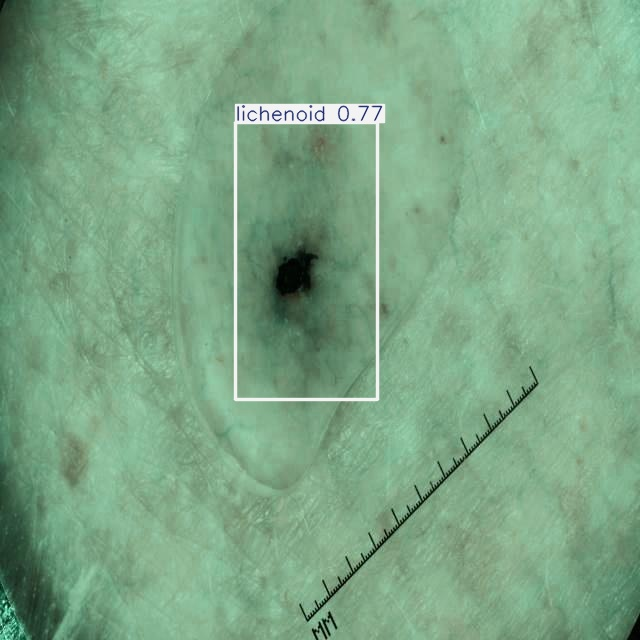

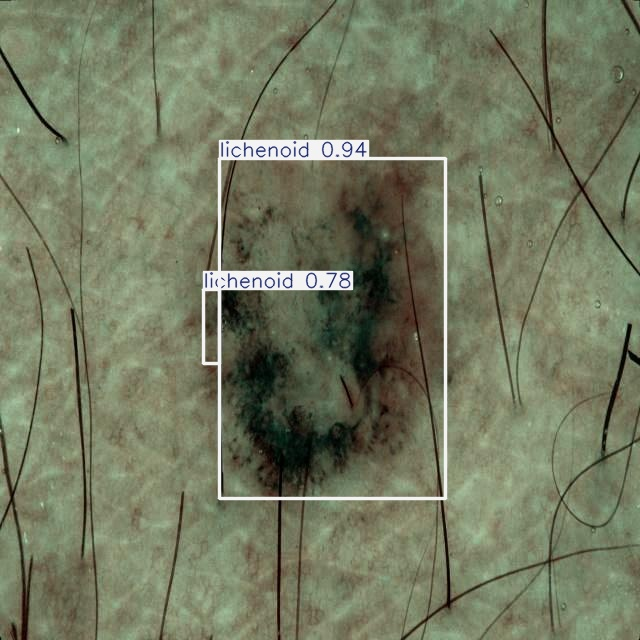

In [13]:
import glob
import os
from IPython.display import Image as IPyImage, display

latest_folder = max(glob.glob('/content/runs/detect/predict*/'), key=os.path.getmtime)
for img in glob.glob(f'{latest_folder}/*.jpg')[:3]:
    display(IPyImage(filename=img, width=600))
    print("\n")

In [14]:

!zip -r /content/runs.zip /content/runs
from google.colab import files
files.download("/content/runs.zip")

  adding: content/runs/ (stored 0%)
  adding: content/runs/detect/ (stored 0%)
  adding: content/runs/detect/val2/ (stored 0%)
  adding: content/runs/detect/val2/val_batch0_labels.jpg (deflated 10%)
  adding: content/runs/detect/val2/val_batch2_pred.jpg (deflated 9%)
  adding: content/runs/detect/val2/R_curve.png (deflated 13%)
  adding: content/runs/detect/val2/val_batch2_labels.jpg (deflated 9%)
  adding: content/runs/detect/val2/val_batch1_labels.jpg (deflated 10%)
  adding: content/runs/detect/val2/val_batch1_pred.jpg (deflated 10%)
  adding: content/runs/detect/val2/confusion_matrix.png (deflated 30%)
  adding: content/runs/detect/val2/PR_curve.png (deflated 14%)
  adding: content/runs/detect/val2/val_batch0_pred.jpg (deflated 10%)
  adding: content/runs/detect/val2/P_curve.png (deflated 11%)
  adding: content/runs/detect/val2/F1_curve.png (deflated 12%)
  adding: content/runs/detect/val2/confusion_matrix_normalized.png (deflated 26%)
  adding: content/runs/detect/train/ (stored 0

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>